# scRNA-seq preprocessing with Seurat: PBMC 10k

From the Cell Ranger count matrix to scaled data, ready for PCA and clustering.

| Step | Question | Main function |
|---|---|---|
| 1. Load | What did the sequencer measure? | `Read10X`, `CreateSeuratObject` |
| 2. Ambient RNA check | How much of each cell's counts is free-floating RNA? | `SoupX` |
| 3. Doublets | Which barcodes hold two cells? | `scDblFinder` |
| 4. QC metrics | Which barcodes look like intact single cells? | `PercentageFeatureSet` |
| 5. Thresholds | Where do we draw the line? | `scuttle::isOutlier` (MAD outliers) |
| 6. Filter | Remove cells and rarely detected genes | `subset` |
| 7. Normalize | Make cells with different depths comparable | `NormalizeData` |
| 8. HVGs | Which genes carry biological signal? | `FindVariableFeatures` |
| 9. Scale + PCA | Give each gene equal weight; first look at structure | `ScaleData`, `RunPCA` |

**Input:** `data/pbmc10_data/` (10x filtered matrix). **Output:** `data/pbmc10k_stage1_preprocessed.rds`, tables in `data/tables/pbmc10k_stage1/`. Kernel: **R 4.4.3 (seurat_env)** (`bash install.sh`).

The numbers in the *Discussion* boxes are from our run of this notebook.

## 0. Setup

All parameters are set here and discussed in the section where they are used.

In [1]:
suppressPackageStartupMessages({
  library(Seurat)
  library(ggplot2)
  library(patchwork)
})
options(repr.plot.width = 12, repr.plot.height = 5)
stage_times <- c(Setup = Sys.time())          # runtime per stage, reported at the end

# Paths: Jupyter runs the notebook in scripts/seurat_analysis/, so the project root is two folders up
base_dir <- normalizePath(file.path(getwd(), "..", ".."))
if (!file.exists(file.path(base_dir, "install.sh"))) stop("Open this notebook from scripts/seurat_analysis/ (project root not found)")
data_dir  <- file.path(base_dir, "data", "pbmc10_data")
table_dir <- file.path(base_dir, "data", "tables", "pbmc10k_stage1")
rds_file  <- file.path(base_dir, "data", "pbmc10k_stage1_preprocessed.rds")
dir.create(table_dir, recursive = TRUE, showWarnings = FALSE)

# Parameters
seed        <- 198716   # every random step uses this seed
min_genes   <- 200      # a barcode with fewer detected genes is not scored or kept
nmads_depth <- 5        # MADs (both tails) for library size and detected genes
nmads_mt    <- 3        # MADs above the median mitochondrial %
min_cells   <- 3        # keep genes detected in at least this many cells
n_hvg       <- 2000     # number of highly variable genes
set.seed(seed)

## 1. Load the count matrix

Cell Ranger's *filtered* matrix holds the barcodes it called as cells. It is a **sparse** genes × barcodes matrix of UMI counts: most entries are zero, so only the non-zero values are stored.

In [2]:
stage_times["1. Load"] <- Sys.time()
counts <- Read10X(data_dir)
pbmc   <- CreateSeuratObject(counts = counts, project = "pbmc10k")
c(genes = nrow(counts), barcodes = ncol(counts), percent_non_zero = round(100 * Matrix::nnzero(counts) / prod(dim(counts)), 1))
rm(counts)
pbmc

genes         barcodes percent_non_zero 
         36601.0          10985.0              7.1

An object of class Seurat 
36601 features across 10985 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

> **Discussion.** 10,985 barcodes × 36,601 genes. Only a few percent of the entries are non-zero: a typical cell detects 1,000–3,000 genes. Why is a sparse format essential here?

## 2. Ambient RNA: a quick SoupX check (no correction here)

Lysed cells release mRNA into the suspension. Every droplet captures some of this **soup** together with its cell, so a cell's counts = its own RNA + ρ × (soup profile), where **ρ** is the contamination fraction. SoupX estimates ρ from genes that most cells cannot express (immunoglobulins outside B / plasma cells, haemoglobins outside red cells): in those cells, any count of these genes must come from the soup.

**Choices:** we have no empty droplets (only the filtered matrix), so the soup profile is approximated by the pooled expression of all cells; without clusters, each cell is its own group (`clusters = FALSE`). We only **estimate** ρ: correcting the counts without clusters is very slow.

In [3]:
stage_times["2. SoupX check"] <- Sys.time()
counts <- LayerData(pbmc, layer = "counts")
sc <- SoupX::SoupChannel(tod = counts, toc = counts, calcSoupProfile = FALSE)
sc <- SoupX::setSoupProfile(sc, data.frame(est = Matrix::rowSums(counts) / sum(counts),
                                           counts = Matrix::rowSums(counts), row.names = rownames(counts)))
soup_genes <- list(IG = c("IGKC", "IGHG1", "IGHG2", "IGHG3", "IGHG4", "IGHA1", "IGHA2", "IGHM", "IGLC2", "IGLC3"),
                   HB = c("HBB", "HBA1", "HBA2"))
use_cells <- suppressMessages(SoupX::estimateNonExpressingCells(sc, soup_genes, clusters = FALSE))
sc <- SoupX::calculateContaminationFraction(sc, soup_genes, useToEst = use_cells, verbose = FALSE)

cat("Contamination fraction rho:", round(100 * sc$metaData$rho[1], 1), "%\n")
head(sc$soupProfile[order(-sc$soupProfile$est), ], 10)          # genes that dominate the soup
rm(sc, counts, use_cells)

Contamination fraction rho: 3.9 %


,est,counts
,<dbl>,<dbl>
MALAT1,0.033070257,3796855
MT-CO1,0.015373945,1765110
B2M,0.011996086,1377292
MT-CO2,0.010330673,1186083
EEF1A1,0.010001143,1148249
MT-CO3,0.009355373,1074107
MT-ATP6,0.008609395,988460
TMSB4X,0.008186285,939882
RPL41,0.007798782,895392


> **Discussion.** ρ ≈ **3.6%**: a typical cell carries a few hundred soup UMIs. The soup is dominated by monocyte genes (*LYZ*, *S100A8/9*): *LYZ* is detected in ~68% of all cells although monocytes are a minority, so much of that signal is soup. Lineage markers with a small soup share (*CD3E*, *MS4A1*) are barely affected. Keep this in mind when you see *LYZ* or immunoglobulins in T cells later.

**Full analysis: correct the counts.** Do this before doublets and QC, and continue the notebook on the corrected counts:
```r
sc <- SoupX::load10X("path/to/cellranger/outs")          # soup from empty droplets + Cell Ranger clusters
sc <- SoupX::autoEstCont(sc)
pbmc <- CreateSeuratObject(SoupX::adjustCounts(sc, roundToInt = TRUE), project = "pbmc10k")
```

## 3. Doublets (scDblFinder)

Cells are loaded into droplets at random, so some droplets get two cells: about **0.8% per 1,000 cells recovered** on a standard 10x chip (~9% here). scDblFinder makes artificial doublets by summing random pairs of cells and trains a classifier to recognise real barcodes that look like them. It runs **before** QC filtering, because it sets the expected doublet rate from the number of cells it is given. Barcodes with < `min_genes` genes are not scored.

Creating ~8708 artificial doublets...

Dimensional reduction

Evaluating kNN...

Training model...

iter=0, 1804 cells excluded from training.

iter=1, 1804 cells excluded from training.

iter=2, 1804 cells excluded from training.

Threshold found:0.277

1194 (11%) doublets called




   doublet not scored    singlet 
      1194        101       9690 

Warning message:
“Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead.”


            CD3E_and_CD14
             FALSE  TRUE
  doublet     72.9  27.1
  not scored 100.0   0.0
  singlet     96.1   3.9

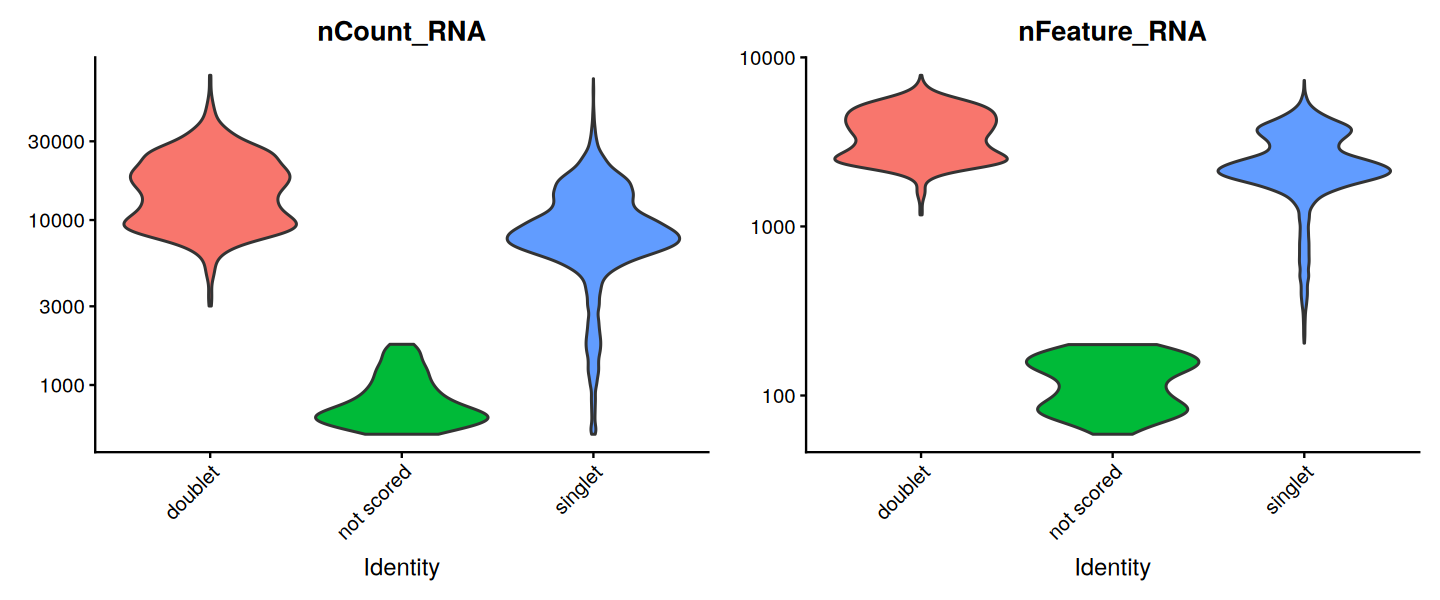

In [4]:
stage_times["3. Doublets"] <- Sys.time()
scored <- pbmc$nFeature_RNA >= min_genes
sce <- SingleCellExperiment::SingleCellExperiment(list(counts = LayerData(pbmc, layer = "counts")[, scored]))
set.seed(seed)
sce <- scDblFinder::scDblFinder(sce, BPPARAM = BiocParallel::SerialParam(RNGseed = seed))
pbmc$scDblFinder.class <- "not scored"
pbmc$scDblFinder.class[scored] <- as.character(sce$scDblFinder.class)
rm(sce)
table(pbmc$scDblFinder.class)

print(VlnPlot(pbmc, c("nCount_RNA", "nFeature_RNA"), group.by = "scDblFinder.class", log = TRUE, pt.size = 0))

# Do called doublets co-express markers of two lineages? (T cell CD3E + monocyte CD14)
both <- LayerData(pbmc, layer = "counts")["CD3E", ] > 0 & LayerData(pbmc, layer = "counts")["CD14", ] > 0
round(100 * prop.table(table(pbmc$scDblFinder.class, CD3E_and_CD14 = both), margin = 1), 1)

> **Discussion.** 1,194 doublets (**11%** of scored barcodes), a bit above the ~9% expected, so this run was loaded densely. Doublets have more UMIs and genes, and 27% of them detect both *CD3E* and *CD14* vs 4% of singlets. Why can't a method like this find **homotypic** doublets (two cells of the same type)? Why do some singlets still co-detect both markers? (Hint: Section 2.)

## 4. QC metrics

| Metric | Low-quality signature | Why |
|---|---|---|
| `nCount_RNA`, `nFeature_RNA` | very low: empty droplet / debris; very high: doublet | library size and complexity |
| `percent.mt` | high | broken cells lose cytoplasmic mRNA but keep mitochondrial transcripts |
| `percent.ribo` | (mostly biology) | high in resting lymphocytes |
| `percent.hb` | high | red blood cells / their RNA |

Warning message:
“Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead.”


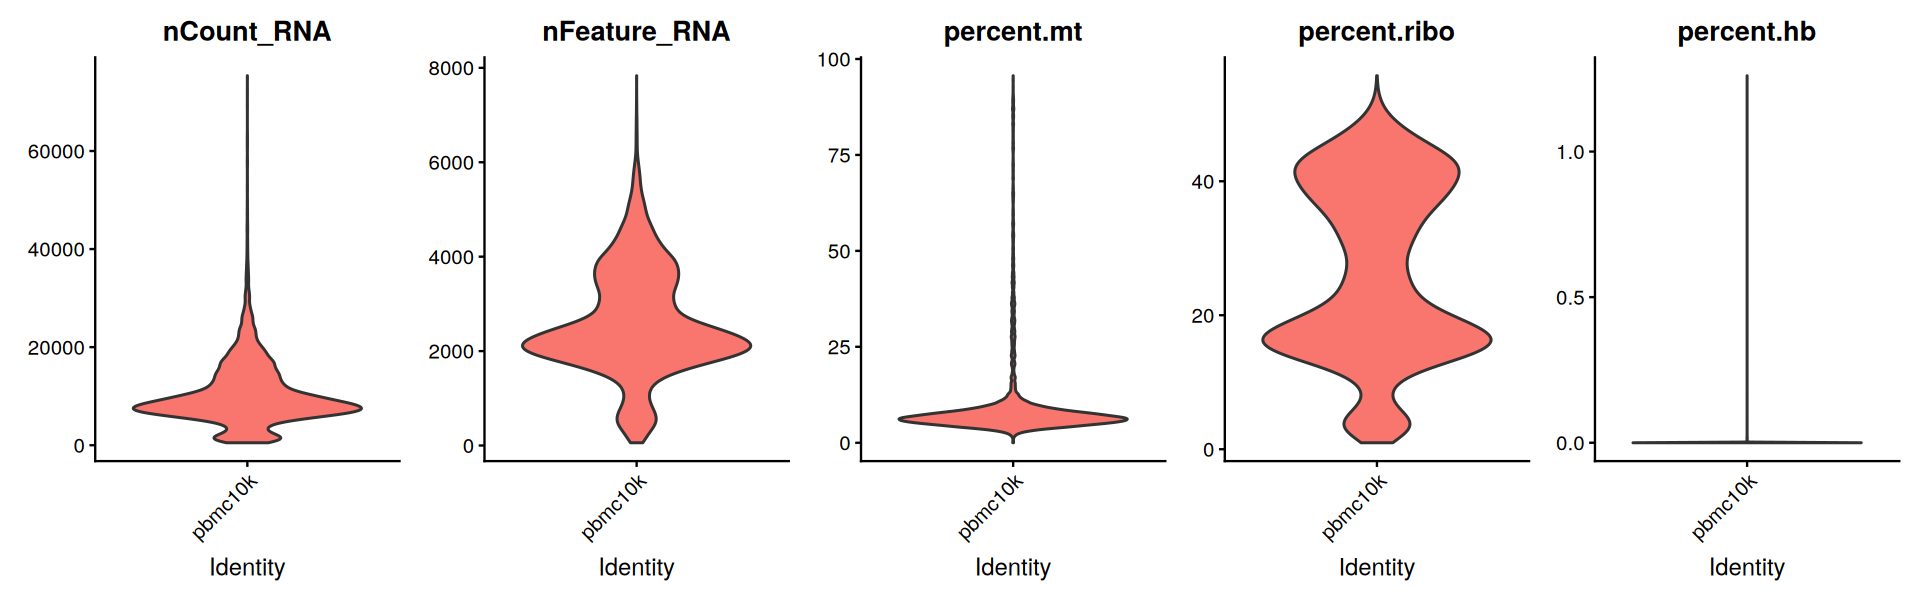

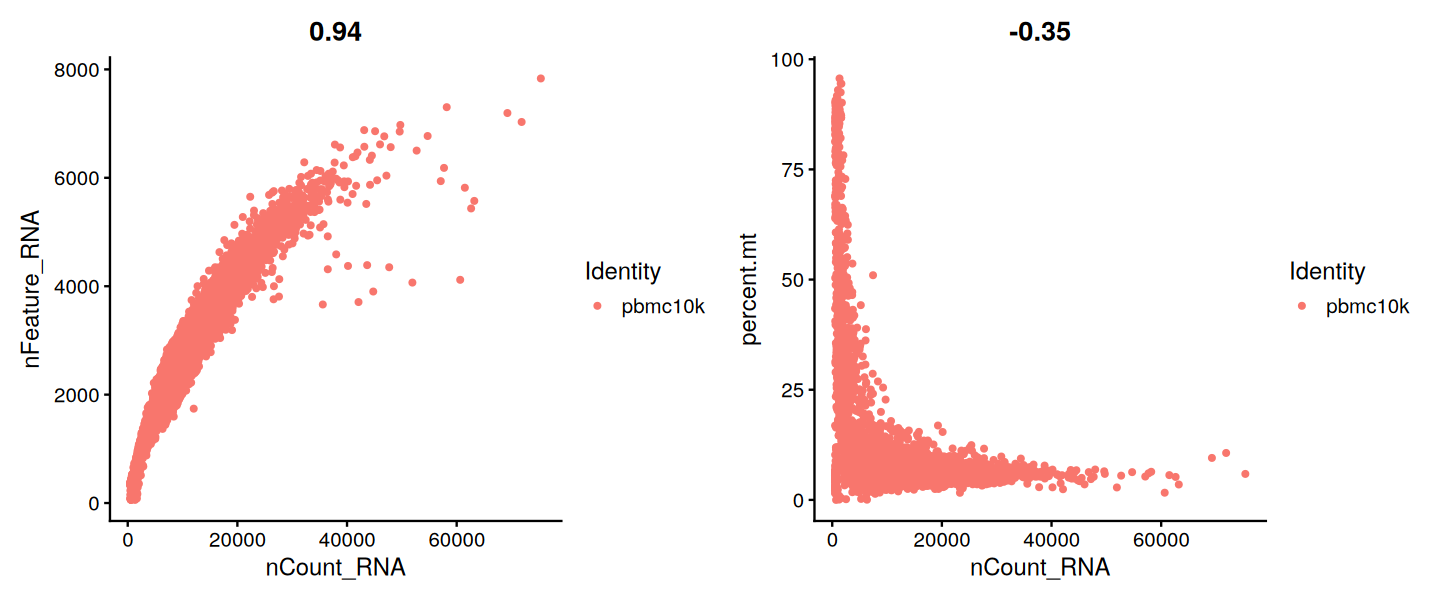

In [5]:
stage_times["4. QC metrics"] <- Sys.time()
pbmc[["percent.mt"]]   <- PercentageFeatureSet(pbmc, pattern = "^MT-")
pbmc[["percent.ribo"]] <- PercentageFeatureSet(pbmc, pattern = "^RP[SL]")
pbmc[["percent.hb"]]   <- PercentageFeatureSet(pbmc, pattern = "^HB[ABDEGMQZ][0-9]?$")

options(repr.plot.width = 16, repr.plot.height = 5)
print(VlnPlot(pbmc, c("nCount_RNA", "nFeature_RNA", "percent.mt", "percent.ribo", "percent.hb"), ncol = 5, pt.size = 0))
options(repr.plot.width = 12, repr.plot.height = 5)
print(FeatureScatter(pbmc, "nCount_RNA", "nFeature_RNA", group.by = "orig.ident") +
      FeatureScatter(pbmc, "nCount_RNA", "percent.mt", group.by = "orig.ident"))

> **Discussion.** UMIs and genes should rise together along one curve; look for cells off that curve. Do the cells with **high %MT** sit at the low-UMI end (the signature of broken cells)? Haemoglobin is almost absent (*HBB* is detected in 0.1% of cells), as expected for a clean PBMC prep.

## 5. Filtering thresholds: MAD outliers

Instead of fixed cut-offs (e.g. %MT < 10), a cell is flagged if it lies more than *k* **median absolute deviations** (MADs) from the median. This adapts to the dataset.

| Metric | Scale | Tail | *k* |
|---|---|---|---|
| `nCount_RNA`, `nFeature_RNA` | log | both | `nmads_depth` = 5 (permissive: we do not want to remove real cell types) |
| `percent.mt` | linear | upper | `nmads_mt` = 3 |

Plus an absolute floor of `min_genes` = 200. Nothing is removed yet.

,lower,higher
nCount_RNA,715.7,107542.7
nFeature_RNA,330.6,16819.7
percent.mt,-Inf,13.0


outlier_counts  outlier_genes     outlier_mt 
           136            161           1037


   kept removed 
   9885    1100 

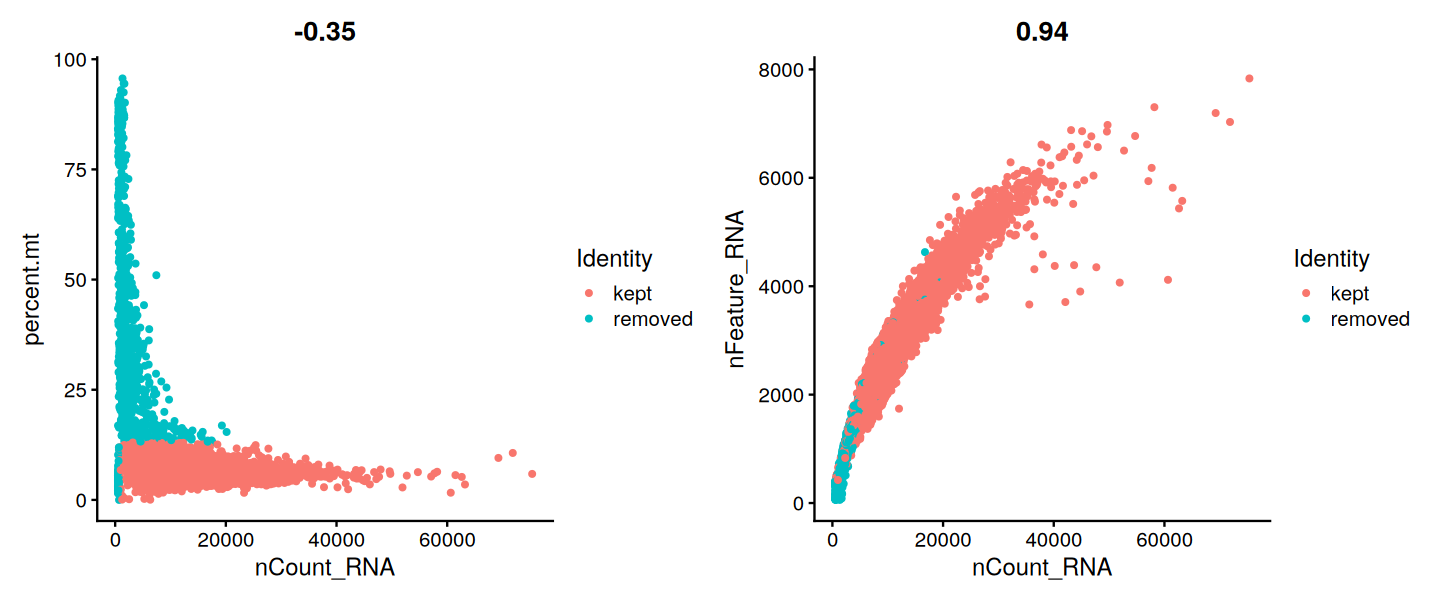

In [6]:
stage_times["5. Thresholds"] <- Sys.time()
out_counts <- scuttle::isOutlier(pbmc$nCount_RNA,   nmads = nmads_depth, log = TRUE, type = "both")
out_genes  <- scuttle::isOutlier(pbmc$nFeature_RNA, nmads = nmads_depth, log = TRUE, type = "both")
out_mt     <- scuttle::isOutlier(pbmc$percent.mt,   nmads = nmads_mt,    type = "higher")
thresholds <- rbind(nCount_RNA = attr(out_counts, "thresholds"), nFeature_RNA = attr(out_genes, "thresholds"),
                    percent.mt = attr(out_mt, "thresholds"))
write.csv(thresholds, file.path(table_dir, "qc_mad_thresholds.csv"))
round(thresholds, 1)

pbmc$qc <- ifelse(out_counts | out_genes | out_mt | pbmc$nFeature_RNA < min_genes, "removed", "kept")
c(outlier_counts = sum(out_counts), outlier_genes = sum(out_genes), outlier_mt = sum(out_mt))
table(pbmc$qc)
print(FeatureScatter(pbmc, "nCount_RNA", "percent.mt", group.by = "qc") +
      FeatureScatter(pbmc, "nCount_RNA", "nFeature_RNA", group.by = "qc"))

> **Discussion.** The MAD bounds were 716–107,543 UMIs, 331–16,820 genes and **%MT ≤ 13.0%**. The depth bounds are wide and remove few cells; %MT removes the most (1,037 cells). A fixed 10% cut-off would have removed ~1,900 more cells. Which rule do you trust for this dataset, and when could a high %MT be biology (e.g. metabolically active cells)?

## 6. Apply the filters

Keep cells that pass QC **and** are singlets; then keep genes detected in at least `min_cells` cells.

In [7]:
stage_times["6. Filter"] <- Sys.time()
table(qc = pbmc$qc, doublet = pbmc$scDblFinder.class)
pbmc <- subset(pbmc, cells = colnames(pbmc)[pbmc$qc == "kept" & pbmc$scDblFinder.class == "singlet"])
genes_keep <- rownames(pbmc)[Matrix::rowSums(LayerData(pbmc, layer = "counts") > 0) >= min_cells]
pbmc <- subset(pbmc, features = genes_keep)
pbmc

         doublet
qc        doublet not scored singlet
  kept       1172          0    8713
  removed      22        101     977

An object of class Seurat 
22180 features across 8713 samples within 1 assay 
Active assay: RNA (22180 features, 0 variable features)
 1 layer present: counts

> **Discussion.** 10,985 → 9,885 pass QC → **8,713 singlets**; 36,601 → **22,180 genes**. Most doublets (1,172) passed the QC thresholds: doublet detection removes cells that QC alone would keep.

## 7. Normalization

`LogNormalize`: each count is divided by the cell's total, multiplied by 10,000 and log-transformed, log(1 + x). This removes differences in sequencing depth, and the log turns multiplicative differences into additive ones. The raw counts stay in the `counts` layer; the result goes to `data`.

In [8]:
stage_times["7. Normalize"] <- Sys.time()
pbmc <- NormalizeData(pbmc, normalization.method = "LogNormalize", scale.factor = 1e4)

Normalizing layer: counts



## 8. Highly variable genes

Most genes vary only by sampling noise. `vst` fits the expected variance for each mean expression and ranks genes by how much they exceed it; the top `n_hvg` = 2,000 are used for PCA. More genes keep more rare signal but add noise.

Finding variable features for layer counts



[1] "IGLC1"  "IGLC3"  "CXCL10" "PTGDS"  "JCHAIN" "IGKC"   "GZMB"   "MZB1"  
 [9] "FCER1A" "TXNDC5" "CDKN1C" "ITM2C"  "LILRA4" "LYPD2"  "GNLY"

When using repel, set xnudge and ynudge to 0 for optimal results



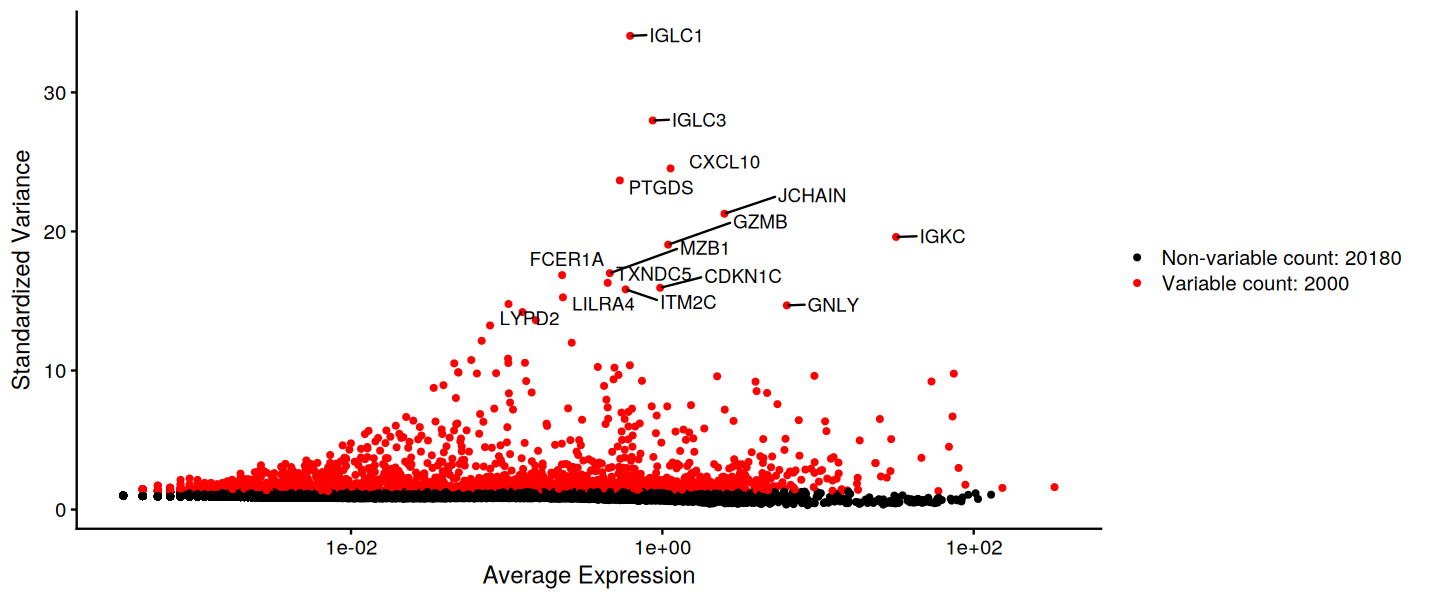

In [9]:
stage_times["8. HVGs"] <- Sys.time()
pbmc <- FindVariableFeatures(pbmc, selection.method = "vst", nfeatures = n_hvg)
top_hvg <- head(VariableFeatures(pbmc), 15)
top_hvg
print(LabelPoints(VariableFeaturePlot(pbmc), points = top_hvg, repel = TRUE))

> **Discussion.** The top HVGs mark known PBMC populations: immunoglobulins (*IGLC1*, *IGKC*, *JCHAIN*, *MZB1*: plasma / B cells), *GZMB*, *GNLY* (NK), *LILRA4*, *ITM2C* (pDCs), *PPBP*, *PF4* (platelets), *CXCL10* (interferon response). Rare populations dominate the list because a gene expressed strongly in few cells has high variance. Part of the immunoglobulin signal is soup (Section 2).

## 9. Scaling and a first PCA

`ScaleData` centres each HVG to mean 0 and scales it to variance 1 (values clipped at 10), so every gene has the same weight in PCA. Without it, a few highly expressed genes would dominate. The elbow plot shows how many PCs carry structure.

Centering and scaling data matrix



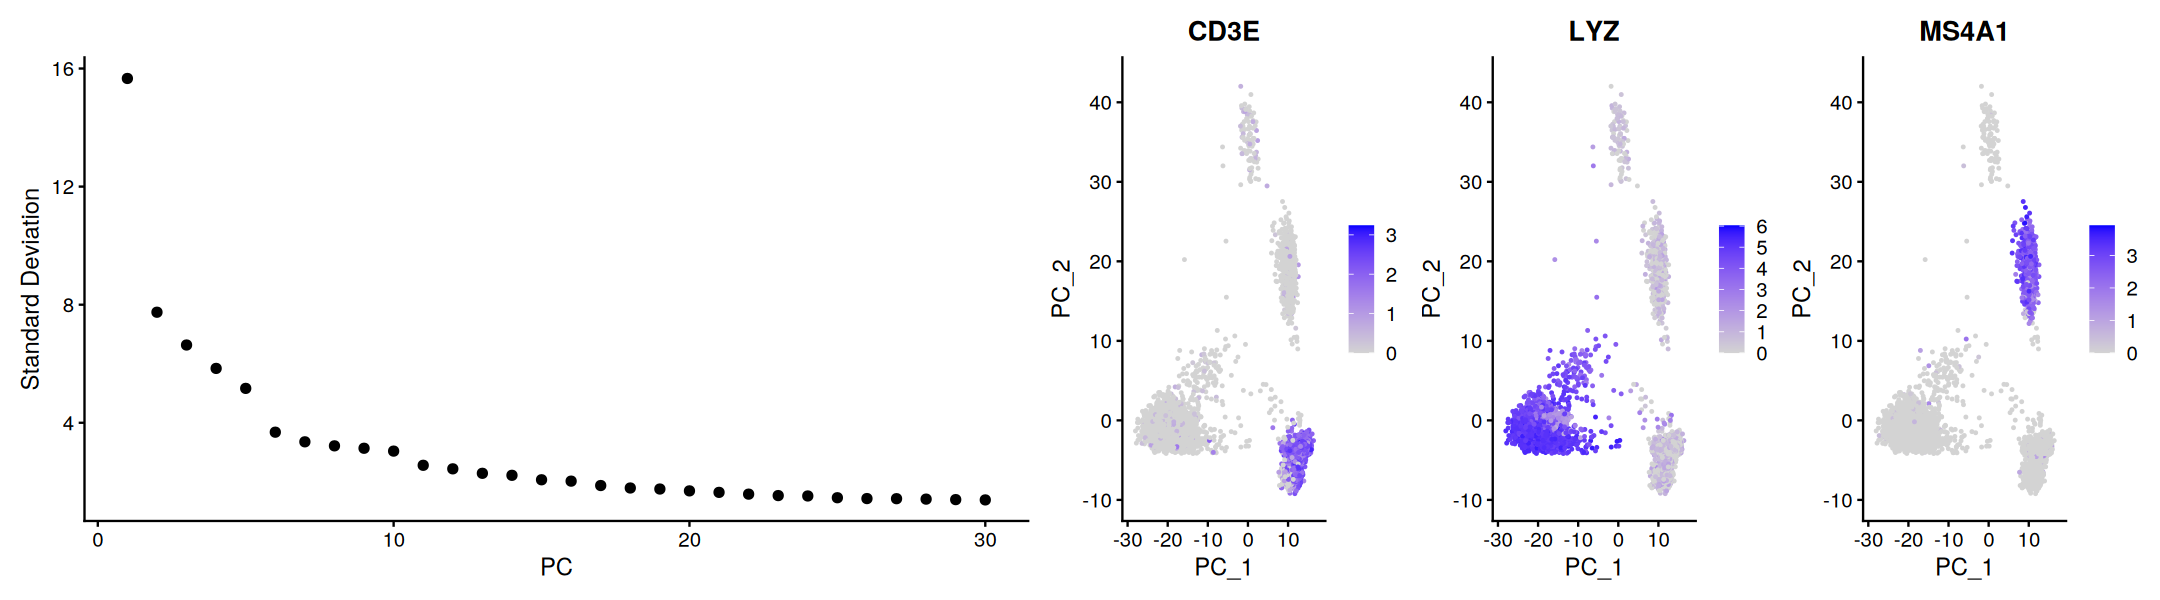

In [10]:
stage_times["9. Scale + PCA"] <- Sys.time()
pbmc <- ScaleData(pbmc)                                   # HVGs only (default)
pbmc <- RunPCA(pbmc, verbose = FALSE)
options(repr.plot.width = 18, repr.plot.height = 5)
print(ElbowPlot(pbmc, ndims = 30) | FeaturePlot(pbmc, c("CD3E", "LYZ", "MS4A1"), reduction = "pca", ncol = 3))

> **Discussion.** Do the first PCs separate T cells (*CD3E*), monocytes (*LYZ*) and B cells (*MS4A1*)? Where does the elbow flatten? That is roughly how many PCs carry structure. Regressing out covariates (e.g. `vars.to.regress = "percent.mt"`) is possible in `ScaleData`, but it can remove real biology. We do not do it here.

## 10. Save

In [11]:
stage_times["10. Save"] <- Sys.time()
saveRDS(pbmc, rds_file)
write.csv(pbmc@meta.data, file.path(table_dir, "cell_metadata.csv"))

## Runtime per stage

Seconds from the start of each stage to the start of the next (meaningful for a run from top to bottom without pauses).

In [12]:
stage_times["End"] <- Sys.time()
data.frame(stage = head(names(stage_times), -1), seconds = round(diff(as.numeric(stage_times)), 1))

stage,seconds
<chr>,<dbl>
Setup,0.1
1. Load,25.0
2. SoupX check,2.5
3. Doublets,69.2
4. QC metrics,5.0
5. Thresholds,1.0
6. Filter,2.4
7. Normalize,3.2
8. HVGs,3.8


> In our run the whole notebook took ~4–5 minutes; loading the matrix and scDblFinder took the longest (~1 min each).

**Take-aways.** QC metrics are diagnostic, not absolute; MAD thresholds adapt to the data; run doublet detection before filtering; normalization removes depth differences; HVGs concentrate the signal; scaling gives every gene equal weight. **Next:** PCA → neighbour graph → clustering → annotation.

In [13]:
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS/LAPACK: /home/sreeram/miniconda3/envs/seurat_env/lib/libopenblasp-r0.3.34.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: Asia/Calcutta
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] patchwork_1.3.2    ggplot2_4.0.3      Seurat_5.5.1       SeuratObject_5.4.0
[5] sp_2.2-3          

loaded via a namespace (and not attached):
  [1] RcppAnnoy_0.0.23            splines_4.4.3              
  [3] later_1.4.8                 pbdZMQ_0.3-14              
  [5] BiocIO_1.